# Machine Learning for Image Steganalysis

## 1. Project Objective

This notebook trains and evaluates two machine learning
classifiers for detecting hidden data in RGB images:

1. Support Vector Machine (SVM)
2. Random Forest

The models use 12 statistical features extracted from
Cover and Stego images.

Class labels:
- 0: Cover image
- 1: Stego image

Training, validation, and test sets are separated
by original source image to prevent data leakage.

In [ ]:
from pathlib import Path
from collections import Counter
import csv
import numpy as np

# Locate the project root
project_root = Path.cwd().resolve()

if project_root.name == "notebooks":
    project_root = project_root.parent

feature_path = project_root / "dataset" / "ucid_features_v3.csv"

# Define the 24 input features
statistics = [
    "lsb_one_ratio",
    "lsb_neighbor_agreement",
    "histogram_imbalance",
    "bitplane_agreement",
    "horizontal_agreement",
    "vertical_agreement",
    "residual_mae",
    "residual_near_zero_ratio"
]

feature_columns = [
    f"{channel}_{stat}"
    for channel in ["r", "g", "b"]
    for stat in statistics
]

# Load feature records
with open(feature_path, "r", encoding="utf-8", newline="") as file:
    records = list(csv.DictReader(file))

assert len(records) == 2100, (
    "Expected 2100 samples. Run full feature extraction first."
)

# Verify that source images do not cross dataset splits
source_splits = {}

for row in records:
    source_id = row["source_id"]
    split = row["split"]

    if source_id in source_splits:
        assert source_splits[source_id] == split
    else:
        source_splits[source_id] = split

assert len(source_splits) == 300

def load_split(split_name):
    """Return features, labels, and metadata for a dataset split."""

    selected = [
        row for row in records
        if row["split"] == split_name
    ]

    X = np.array([
        [float(row[column]) for column in feature_columns]
        for row in selected
    ], dtype=np.float64)

    y = np.array([
        int(row["label"]) for row in selected
    ], dtype=np.int64)

    assert np.isfinite(X).all()
    assert set(np.unique(y)) == {0, 1}

    return X, y, selected


X_train, y_train, train_rows = load_split("train")
X_val, y_val, val_rows = load_split("validation")
X_test, y_test, test_rows = load_split("test")

print("Training:", X_train.shape, Counter(y_train))
print("Validation:", X_val.shape, Counter(y_val))
print("Testing:", X_test.shape, Counter(y_test))
print("Feature count:", len(feature_columns))

print("Dataset loaded successfully.")

KeyError: 'r_vertical_agreementresidual_mae'

## 2. SVM Classifier

An SVM classifier is trained using standardized
statistical image features.

Class balancing is applied to account for the
unequal numbers of Cover and Stego samples.

Only training data is used to fit the model.


In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

# Build an SVM classification pipeline
svm_model = make_pipeline(
    StandardScaler(),
    SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale",
        class_weight="balanced"
    )
)

# Train using only the training dataset
svm_model.fit(X_train, y_train)

print("SVM training completed.")

SVM training completed.


## 3. Random Forest Classifier

Random Forest combines multiple decision trees
to classify Cover and Stego images.

The same training features and labels are used
for a fair comparison with SVM.


In [ ]:
from sklearn.ensemble import RandomForestClassifier

# Create the Random Forest classifier
rf_model = RandomForestClassifier(
    n_estimators=200,
    min_samples_leaf=2,
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1
)

# Train using the same training dataset
rf_model.fit(X_train, y_train)

print("Random Forest training completed.")

Random Forest training completed.


## 4. Validation and Model Comparison

Both models are evaluated on the validation dataset.

Evaluation metrics include:

- Accuracy
- Balanced Accuracy
- Macro F1-score
- Confusion Matrix

The final model is selected using validation performance,
without using test data for model selection.

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    confusion_matrix,
    classification_report
)

models = {
    "SVM": svm_model,
    "Random Forest": rf_model
}

validation_scores = {}

for name, model in models.items():

    predictions = model.predict(X_val)

    accuracy = accuracy_score(y_val, predictions)
    balanced_acc = balanced_accuracy_score(y_val, predictions)
    macro_f1 = f1_score(
        y_val,
        predictions,
        average="macro",
        zero_division=0
    )

    validation_scores[name] = {
        "balanced_accuracy": balanced_acc,
        "macro_f1": macro_f1
    }

    print(f"\n--- {name} Validation Results ---")
    print(f"Accuracy: {accuracy:.4f}")
    print(f"Balanced Accuracy: {balanced_acc:.4f}")
    print(f"Macro F1-score: {macro_f1:.4f}")

    print("Confusion Matrix:")
    print(confusion_matrix(y_val, predictions, labels=[0, 1]))

    print(classification_report(
        y_val,
        predictions,
        labels=[0, 1],
        target_names=["Cover", "Stego"],
        zero_division=0
    ))

# Select the model using validation results only
best_name = max(
    validation_scores,
    key=lambda name: (
        validation_scores[name]["balanced_accuracy"],
        validation_scores[name]["macro_f1"]
    )
)

best_model = models[best_name]

print("\nSelected model:", best_name)


--- SVM Validation Results ---
Accuracy: 0.8159
Balanced Accuracy: 0.8556
Macro F1-score: 0.7337
Confusion Matrix:
[[ 41   4]
 [ 54 216]]
              precision    recall  f1-score   support

       Cover       0.43      0.91      0.59        45
       Stego       0.98      0.80      0.88       270

    accuracy                           0.82       315
   macro avg       0.71      0.86      0.73       315
weighted avg       0.90      0.82      0.84       315


--- Random Forest Validation Results ---
Accuracy: 0.8762
Balanced Accuracy: 0.6222
Macro F1-score: 0.6561
Confusion Matrix:
[[ 12  33]
 [  6 264]]
              precision    recall  f1-score   support

       Cover       0.67      0.27      0.38        45
       Stego       0.89      0.98      0.93       270

    accuracy                           0.88       315
   macro avg       0.78      0.62      0.66       315
weighted avg       0.86      0.88      0.85       315


Selected model: SVM


In [ ]:
## 5. Final Test Evaluation

# Evaluate the selected model on unseen test images
test_predictions = best_model.predict(X_test)

print("Selected model:", best_name)

print("Test Balanced Accuracy:", round(
    balanced_accuracy_score(y_test, test_predictions), 4
))

print("Test Macro F1-score:", round(
    f1_score(
        y_test,
        test_predictions,
        average="macro",
        zero_division=0
    ), 4
))

print("\nTest Confusion Matrix:")
print(confusion_matrix(
    y_test,
    test_predictions,
    labels=[0, 1]
))

print("\nFinal Classification Report:")
print(classification_report(
    y_test,
    test_predictions,
    labels=[0, 1],
    target_names=["Cover", "Stego"],
    zero_division=0
))

Selected model: SVM
Test Balanced Accuracy: 0.8167
Test Macro F1-score: 0.6704

Test Confusion Matrix:
[[ 41   4]
 [ 75 195]]

Final Classification Report:
              precision    recall  f1-score   support

       Cover       0.35      0.91      0.51        45
       Stego       0.98      0.72      0.83       270

    accuracy                           0.75       315
   macro avg       0.67      0.82      0.67       315
weighted avg       0.89      0.75      0.79       315



## 5. Detection Performance by Embedding Method and Payload Rate

This section analyzes detection performance across
different embedding algorithms and payload rates.

The analysis is performed on validation data only.

The goal is to identify which steganographic conditions
are more difficult for the classifiers to detect.

In [ ]:
import numpy as np

for model_name, model in models.items():

    predictions = model.predict(X_val)

    print(f"\n--- {model_name} Error Analysis ---")

    # Calculate false positive rate for cover images
    cover_indices = np.where(y_val == 0)[0]

    false_positives = np.sum(
        predictions[cover_indices] == 1
    )

    false_positive_rate = (
        false_positives / len(cover_indices)
    )

    print(
        f"Cover false positive rate: "
        f"{false_positive_rate:.2%}"
    )

    # Analyze detection rates by method and payload size
    for method in ["sequential", "prng"]:

        for rate in [0.05, 0.15, 0.30]:

            indices = [
                index
                for index, row in enumerate(val_rows)
                if row["label"] == "1"
                and row["method"] == method
                and abs(
                    float(row["payload_rate"]) - rate
                ) < 1e-9
            ]

            if not indices:
                continue

            detected = np.sum(
                predictions[indices] == 1
            )

            detection_rate = detected / len(indices)

            print(
                f"{method:12s} | "
                f"Payload: {rate:.0%} | "
                f"Detection rate: {detection_rate:.2%}"
            )


--- SVM Error Analysis ---
Cover false positive rate: 8.89%
sequential   | Payload: 5% | Detection rate: 82.22%
sequential   | Payload: 15% | Detection rate: 100.00%
sequential   | Payload: 30% | Detection rate: 100.00%
prng         | Payload: 5% | Detection rate: 24.44%
prng         | Payload: 15% | Detection rate: 80.00%
prng         | Payload: 30% | Detection rate: 93.33%

--- Random Forest Error Analysis ---
Cover false positive rate: 73.33%
sequential   | Payload: 5% | Detection rate: 100.00%
sequential   | Payload: 15% | Detection rate: 100.00%
sequential   | Payload: 30% | Detection rate: 100.00%
prng         | Payload: 5% | Detection rate: 86.67%
prng         | Payload: 15% | Detection rate: 100.00%
prng         | Payload: 30% | Detection rate: 100.00%


## 6. Model Performance Visualization

This section visualizes the validation performance of
SVM and Random Forest.

The figures include:
- A comparison of classification metrics
- The SVM validation confusion matrix

All figures are generated from actual model predictions.

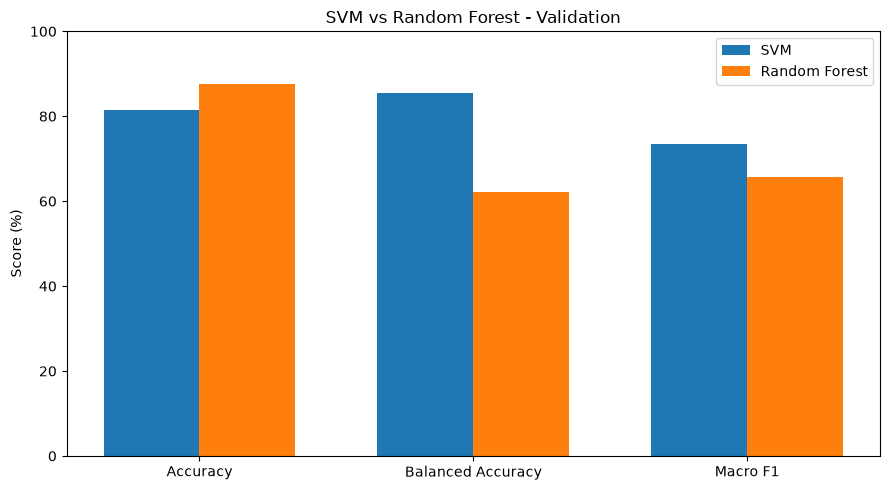

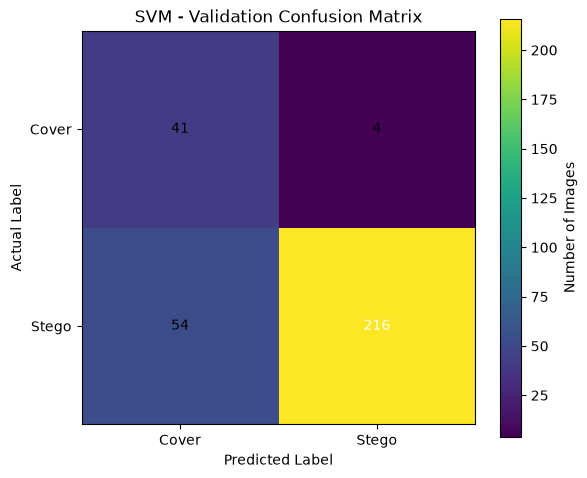

Figures saved successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

from pathlib import Path
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    confusion_matrix
)

# Create an output directory for figures
figures_dir = project_root / "dataset" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

# Calculate validation metrics
metric_results = {}

for name, model in models.items():
    predictions = model.predict(X_val)

    metric_results[name] = [
        accuracy_score(y_val, predictions),
        balanced_accuracy_score(y_val, predictions),
        f1_score(
            y_val,
            predictions,
            average="macro",
            zero_division=0
        )
    ]

# Figure 1: Model comparison
metric_names = [
    "Accuracy",
    "Balanced Accuracy",
    "Macro F1"
]

x = np.arange(len(metric_names))
width = 0.35

plt.figure(figsize=(9, 5))

plt.bar(
    x - width / 2,
    np.array(metric_results["SVM"]) * 100,
    width,
    label="SVM"
)

plt.bar(
    x + width / 2,
    np.array(metric_results["Random Forest"]) * 100,
    width,
    label="Random Forest"
)

plt.xticks(x, metric_names)
plt.ylabel("Score (%)")
plt.ylim(0, 100)
plt.title("SVM vs Random Forest - Validation")
plt.legend()
plt.tight_layout()

plt.savefig(
    figures_dir / "model_comparison.png",
    dpi=300
)

plt.show()


# Figure 2: SVM confusion matrix
svm_predictions = svm_model.predict(X_val)

cm = confusion_matrix(
    y_val,
    svm_predictions,
    labels=[0, 1]
)

plt.figure(figsize=(6, 5))
plt.imshow(cm)
plt.colorbar(label="Number of Images")

plt.xticks([0, 1], ["Cover", "Stego"])
plt.yticks([0, 1], ["Cover", "Stego"])

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("SVM - Validation Confusion Matrix")

for i in range(2):
    for j in range(2):
        plt.text(
            j, i, str(cm[i, j]),
            ha="center",
            va="center",
            color="white" if cm[i, j] > cm.max() / 2 else "black"
        )

plt.tight_layout()

plt.savefig(
    figures_dir / "svm_confusion_matrix.png",
    dpi=300
)

plt.show()

print("Figures saved successfully.")

## 7. Detection Analysis by Payload Rate and Embedding Method

This section investigates how payload size and embedding
method affect steganalysis performance.

Both SVM and Random Forest are evaluated using the
validation dataset.

The detection rate is calculated separately for:
- Sequential LSB at 5%, 15%, and 30% payload
- PRNG-based LSB at 5%, 15%, and 30% payload

This analysis helps identify limitations of the
current statistical feature set.

In [ ]:
import numpy as np
import csv
from pathlib import Path

# Analyze validation data only
payload_rates = [0.05, 0.15, 0.30]
embedding_methods = ["sequential", "prng"]

analysis_results = []

for model_name, model in models.items():

    predictions = model.predict(X_val)

    print(f"\n--- {model_name} Detection Analysis ---")

    # Calculate cover false positive rate
    cover_mask = (y_val == 0)

    false_positive_rate = np.mean(
        predictions[cover_mask] == 1
    )

    print(f"Cover FPR: {false_positive_rate:.2%}")

    for method in embedding_methods:

        for rate in payload_rates:

            # Select stego samples for the given method and rate
            indices = [
                index
                for index, row in enumerate(val_rows)
                if int(row["label"]) == 1
                and row["method"] == method
                and abs(
                    float(row["payload_rate"]) - rate
                ) < 1e-9
            ]

            if not indices:
                raise ValueError(
                    f"No samples for {method}, rate={rate}"
                )

            # Calculate the stego detection rate
            detected = sum(
                predictions[index] == 1
                for index in indices
            )

            detection_rate = detected / len(indices)

            analysis_results.append({
                "model": model_name,
                "method": method,
                "payload_rate": rate,
                "samples": len(indices),
                "detected": detected,
                "detection_rate": detection_rate
            })

            print(
                f"{method:12s} | "
                f"Payload: {rate:.0%} | "
                f"Detected: {detected}/{len(indices)} | "
                f"Rate: {detection_rate:.2%}"
            )

# Save reproducible analysis results
output_file = (
    project_root / "dataset" / "detection_analysis.csv"
)

with open(
    output_file, "w",
    newline="", encoding="utf-8"
) as file:

    writer = csv.DictWriter(
        file,
        fieldnames=list(analysis_results[0].keys())
    )
    writer.writeheader()
    writer.writerows(analysis_results)

print("\nAnalysis saved:", output_file)


--- SVM Detection Analysis ---
Cover FPR: 8.89%
sequential   | Payload: 5% | Detected: 37/45 | Rate: 82.22%
sequential   | Payload: 15% | Detected: 45/45 | Rate: 100.00%
sequential   | Payload: 30% | Detected: 45/45 | Rate: 100.00%
prng         | Payload: 5% | Detected: 11/45 | Rate: 24.44%
prng         | Payload: 15% | Detected: 36/45 | Rate: 80.00%
prng         | Payload: 30% | Detected: 42/45 | Rate: 93.33%

--- Random Forest Detection Analysis ---
Cover FPR: 73.33%
sequential   | Payload: 5% | Detected: 45/45 | Rate: 100.00%
sequential   | Payload: 15% | Detected: 45/45 | Rate: 100.00%
sequential   | Payload: 30% | Detected: 45/45 | Rate: 100.00%
prng         | Payload: 5% | Detected: 39/45 | Rate: 86.67%
prng         | Payload: 15% | Detected: 45/45 | Rate: 100.00%
prng         | Payload: 30% | Detected: 45/45 | Rate: 100.00%

Analysis saved: C:\Users\hp\Projects\image-steganography\dataset\detection_analysis.csv


## 8. SVM Hyperparameter Tuning

This experiment evaluates different SVM configurations
using the validation dataset.

The parameters C and gamma are varied while keeping
the feature set and training data unchanged.

The main selection metric is Balanced Accuracy.

The test dataset is not used during tuning.

In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import balanced_accuracy_score, f1_score
import numpy as np

# Define candidate hyperparameters
c_values = [0.1, 1, 10]
gamma_values = ["scale", 0.1, 1]

tuning_results = []

for c in c_values:
    for gamma in gamma_values:

        model = make_pipeline(
            StandardScaler(),
            SVC(
                kernel="rbf",
                C=c,
                gamma=gamma,
                class_weight="balanced"
            )
        )

        model.fit(X_train, y_train)
        predictions = model.predict(X_val)

        balanced_acc = balanced_accuracy_score(
            y_val, predictions
        )

        macro_f1 = f1_score(
            y_val,
            predictions,
            average="macro",
            zero_division=0
        )

        cover_mask = y_val == 0
        cover_fpr = np.mean(
            predictions[cover_mask] == 1
        )

        tuning_results.append({
            "C": c,
            "gamma": gamma,
            "balanced_accuracy": balanced_acc,
            "macro_f1": macro_f1,
            "cover_fpr": cover_fpr
        })

# Rank configurations by validation performance
tuning_results.sort(
    key=lambda row: (
        row["balanced_accuracy"],
        row["macro_f1"]
    ),
    reverse=True
)

for result in tuning_results:
    print(
        f"C={result['C']}, "
        f"gamma={result['gamma']}, "
        f"Balanced Accuracy={result['balanced_accuracy']:.4f}, "
        f"Macro F1={result['macro_f1']:.4f}, "
        f"Cover FPR={result['cover_fpr']:.2%}"
    )

print("\nBest configuration:", tuning_results[0])

C=1, gamma=0.1, Balanced Accuracy=0.8574, Macro F1=0.7369, Cover FPR=8.89%
C=1, gamma=scale, Balanced Accuracy=0.8556, Macro F1=0.7337, Cover FPR=8.89%
C=10, gamma=scale, Balanced Accuracy=0.8481, Macro F1=0.7480, Cover FPR=13.33%
C=10, gamma=0.1, Balanced Accuracy=0.8389, Macro F1=0.7596, Cover FPR=17.78%
C=0.1, gamma=0.1, Balanced Accuracy=0.8037, Macro F1=0.6075, Cover FPR=0.00%
C=0.1, gamma=1, Balanced Accuracy=0.7963, Macro F1=0.6078, Cover FPR=2.22%
C=0.1, gamma=scale, Balanced Accuracy=0.7870, Macro F1=0.5842, Cover FPR=0.00%
C=1, gamma=1, Balanced Accuracy=0.7593, Macro F1=0.7666, Cover FPR=42.22%
C=10, gamma=1, Balanced Accuracy=0.6815, Macro F1=0.7134, Cover FPR=60.00%

Best configuration: {'C': 1, 'gamma': 0.1, 'balanced_accuracy': 0.8574074074074074, 'macro_f1': 0.7369192222596668, 'cover_fpr': np.float64(0.08888888888888889)}


## 9. Tuned SVM Performance Analysis

This section evaluates the selected SVM configuration
on the validation dataset.

Detection rates are analyzed separately for Sequential
and PRNG embedding at different payload rates.

The test dataset is not used in this experiment.

In [ ]:
# Train the best SVM configuration
best_config = tuning_results[0]

best_svm = make_pipeline(
    StandardScaler(),
    SVC(
        kernel="rbf",
        C=best_config["C"],
        gamma=best_config["gamma"],
        class_weight="balanced"
    )
)

best_svm.fit(X_train, y_train)

# Predict validation labels
predictions = best_svm.predict(X_val)

print("--- Tuned SVM Validation ---")

print(
    "Balanced Accuracy:",
    round(balanced_accuracy_score(y_val, predictions), 4)
)

# Calculate false positive rate
cover_mask = y_val == 0

print(
    "Cover FPR:",
    f"{np.mean(predictions[cover_mask] == 1):.2%}"
)

# Analyze embedding methods and payload rates
for method in ["sequential", "prng"]:

    for rate in [0.05, 0.15, 0.30]:

        indices = [
            i for i, row in enumerate(val_rows)
            if int(row["label"]) == 1
            and row["method"] == method
            and abs(float(row["payload_rate"]) - rate) < 1e-9
        ]

        detected = sum(predictions[i] == 1 for i in indices)

        detection_rate = detected / len(indices)

        print(
            f"{method:12s} | "
            f"Payload: {rate:.0%} | "
            f"Detected: {detected}/{len(indices)} | "
            f"Detection Rate: {detection_rate:.2%}"
        )

--- Tuned SVM Validation ---
Balanced Accuracy: 0.8574
Cover FPR: 8.89%
sequential   | Payload: 5% | Detected: 37/45 | Detection Rate: 82.22%
sequential   | Payload: 15% | Detected: 45/45 | Detection Rate: 100.00%
sequential   | Payload: 30% | Detected: 45/45 | Detection Rate: 100.00%
prng         | Payload: 5% | Detected: 12/45 | Detection Rate: 26.67%
prng         | Payload: 15% | Detected: 36/45 | Detection Rate: 80.00%
prng         | Payload: 30% | Detected: 42/45 | Detection Rate: 93.33%


## 10. PRNG Low-Payload Detection Analysis

This experiment investigates why the tuned SVM struggles
to detect PRNG-based steganography at a 5% payload rate.

The analysis compares SVM decision scores for:

- Cover images
- PRNG stego images with a 5% payload rate

Only the validation dataset is used.

The goal is to examine score separation and identify
whether improved statistical features are needed.

Cover samples: 45
PRNG 5% samples: 45
ROC AUC: 0.7091


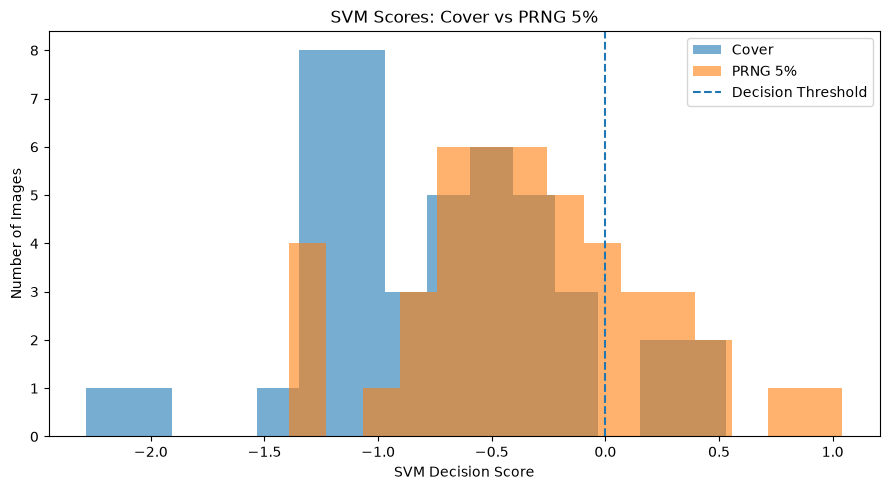

In [ ]:
from sklearn.metrics import roc_auc_score
import numpy as np
import matplotlib.pyplot as plt

# Calculate the SVM decision scores
scores = best_svm.decision_function(X_val)

# Select cover samples
cover_indices = [
    i for i, row in enumerate(val_rows)
    if int(row["label"]) == 0
]

# Select PRNG samples with a 5% payload
prng_indices = [
    i for i, row in enumerate(val_rows)
    if int(row["label"]) == 1
    and row["method"] == "prng"
    and abs(float(row["payload_rate"]) - 0.05) < 1e-9
]

cover_scores = scores[cover_indices]
prng_scores = scores[prng_indices]

# Prepare labels and scores for ROC AUC
comparison_scores = np.concatenate([
    cover_scores,
    prng_scores
])

comparison_labels = np.concatenate([
    np.zeros(len(cover_scores)),
    np.ones(len(prng_scores))
])

auc = roc_auc_score(
    comparison_labels,
    comparison_scores
)

print("Cover samples:", len(cover_scores))
print("PRNG 5% samples:", len(prng_scores))
print("ROC AUC:", round(auc, 4))

# Plot decision score distributions
plt.figure(figsize=(9, 5))

plt.hist(
    cover_scores,
    bins=15,
    alpha=0.6,
    label="Cover"
)

plt.hist(
    prng_scores,
    bins=15,
    alpha=0.6,
    label="PRNG 5%"
)

# Default SVM classification threshold
plt.axvline(
    0,
    linestyle="--",
    label="Decision Threshold"
)

plt.xlabel("SVM Decision Score")
plt.ylabel("Number of Images")
plt.title("SVM Scores: Cover vs PRNG 5%")
plt.legend()
plt.tight_layout()

plt.show()

## 11. SVM Decision Threshold Analysis

This experiment evaluates the relationship between
PRNG low-payload detection and cover false positives.

Different decision thresholds are examined using
validation data only.

The purpose is to understand the trade-off between
detection sensitivity and false positive rate.

In [ ]:
from sklearn.metrics import roc_auc_score
import numpy as np

# Measure score separation
auc = roc_auc_score(
    comparison_labels,
    comparison_scores
)

print(f"ROC AUC: {auc:.4f}")
print("\nThreshold Analysis")
print("-" * 55)

thresholds = [-0.50, -0.25, 0.00, 0.25]

for threshold in thresholds:

    # PRNG detection rate
    detection_rate = np.mean(
        prng_scores >= threshold
    )

    # Cover false positive rate
    false_positive_rate = np.mean(
        cover_scores >= threshold
    )

    print(
        f"Threshold: {threshold:+.2f} | "
        f"PRNG Detection: {detection_rate:.2%} | "
        f"Cover FPR: {false_positive_rate:.2%}"
    )
    

ROC AUC: 0.7091

Threshold Analysis
-------------------------------------------------------
Threshold: -0.50 | PRNG Detection: 62.22% | Cover FPR: 33.33%
Threshold: -0.25 | PRNG Detection: 42.22% | Cover FPR: 17.78%
Threshold: +0.00 | PRNG Detection: 26.67% | Cover FPR: 8.89%
Threshold: +0.25 | PRNG Detection: 13.33% | Cover FPR: 6.67%


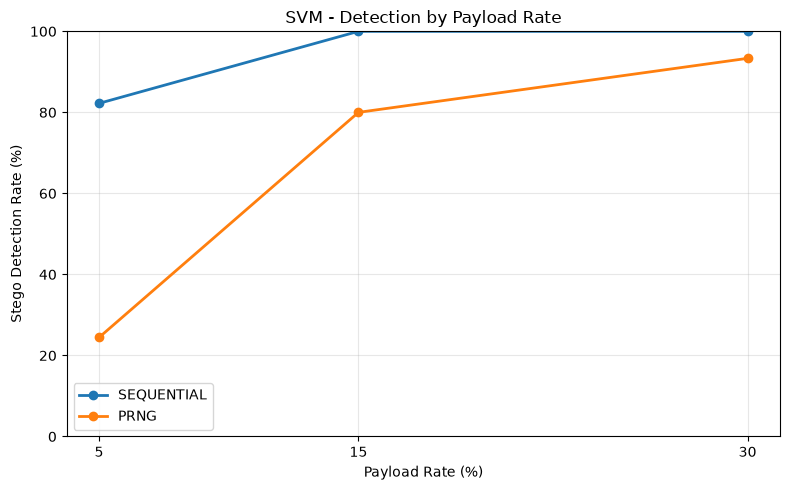

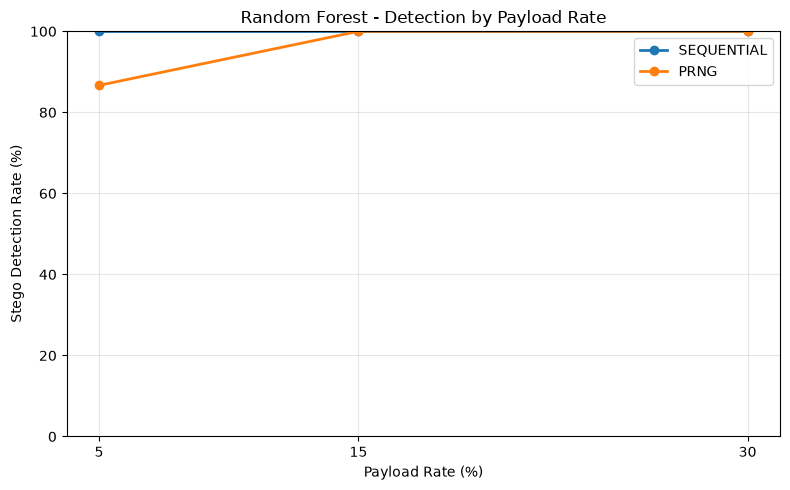

Detection analysis figures saved.


In [ ]:
import matplotlib.pyplot as plt

figures_dir = project_root / "dataset" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

for model_name in models:

    plt.figure(figsize=(8, 5))

    for method in embedding_methods:

        subset = [
            row for row in analysis_results
            if row["model"] == model_name
            and row["method"] == method
        ]

        subset = sorted(
            subset,
            key=lambda row: row["payload_rate"]
        )

        x = [row["payload_rate"] * 100 for row in subset]
        y = [row["detection_rate"] * 100 for row in subset]

        plt.plot(
            x, y,
            marker="o",
            linewidth=2,
            label=method.upper()
        )

    plt.xlabel("Payload Rate (%)")
    plt.ylabel("Stego Detection Rate (%)")
    plt.title(f"{model_name} - Detection by Payload Rate")
    plt.xticks([5, 15, 30])
    plt.ylim(0, 100)
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()

    filename = (
        "svm_payload_analysis.png"
        if model_name == "SVM"
        else "rf_payload_analysis.png"
    )

    plt.savefig(figures_dir / filename, dpi=300)
    plt.show()

print("Detection analysis figures saved.")